In [1]:
import os
import re
import math
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import gutenberg

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence

from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_LEN = 20
EMBED_DIM = 50
HIDDEN_DIM = 64
PAD_IDX = 0
UNK_IDX = 1
BATCH_SIZE = 128

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Device:", DEVICE)

Device: cuda


## Section 1: Data Collection, Preprocessing & Dynamic Sequence Batching

### Task 1.1: Data Collection

In [2]:
nltk.download("gutenberg", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

raw_text = gutenberg.raw("carroll-alice.txt")
sentences = nltk.sent_tokenize(raw_text)

raw_words = nltk.word_tokenize(raw_text)
print("Total sentence count:", len(sentences))
print("Total raw word count:", len(raw_words))
print("Raw unique vocabulary size:", len(set(token.lower() for token in raw_words)))

Total sentence count: 1625
Total raw word count: 33535
Raw unique vocabulary size: 2808


### Task 1.2: Tokenization, Truncation, and Dynamic Sequence Generation

In [3]:
def clean_and_tokenize(text):
    """Lowercase and retain only alphanumeric tokens and . , ! ? punctuation."""
    text = text.lower()
    return re.findall(r"[a-z0-9]+|[.,!?]", text)

cleaned_token_sentences = [clean_and_tokenize(sentence) for sentence in sentences]
cleaned_token_sentences = [tokens for tokens in cleaned_token_sentences if tokens]

frequency_table = Counter(token for sentence in cleaned_token_sentences for token in sentence)

word2idx = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}
# Frequency-first ordering; alphabetical tie-break makes the mapping reproducible.
for word, _ in sorted(frequency_table.items(), key=lambda item: (-item[1], item[0])):
    word2idx[word] = len(word2idx)
idx2word = {idx: word for word, idx in word2idx.items()}

print("Cleaned vocabulary size (including PAD/UNK):", len(word2idx))
print("Most common tokens:", frequency_table.most_common(10))

Cleaned vocabulary size (including PAD/UNK): 2576
Most common tokens: [(',', 2418), ('the', 1642), ('.', 988), ('and', 872), ('to', 729), ('a', 632), ('it', 595), ('she', 553), ('i', 545), ('of', 514)]


In [4]:
indexed_sentences = [
    [word2idx.get(token, UNK_IDX) for token in tokens]
    for tokens in cleaned_token_sentences
]

training_pairs = []
for sentence_ids in indexed_sentences:
    for target_position in range(1, len(sentence_ids)):
        context = sentence_ids[:target_position]
        context = context[-MAX_LEN:]  # left truncation
        target = sentence_ids[target_position]
        training_pairs.append((context, target))

print("Total generated (X, y) pairs:", len(training_pairs))

Total generated (X, y) pairs: 29769


In [5]:
# Worked example: deliberately choose a sentence long enough to demonstrate truncation.
example_index = next(
    (i for i, tokens in enumerate(cleaned_token_sentences) if len(tokens) > MAX_LEN + 1),
    0,
)
example_raw = sentences[example_index]
example_tokens = cleaned_token_sentences[example_index]
example_ids = indexed_sentences[example_index]

print("RAW TEXT:")
print(example_raw)
print("\nCLEANED TOKENS:")
print(example_tokens)
print("\nGENERATED (X, y) PAIRS:")

for target_position in range(1, len(example_ids)):
    full_context = example_ids[:target_position]
    context = full_context[-MAX_LEN:]
    target = example_ids[target_position]
    context_words = [idx2word[idx] for idx in context]
    target_word = idx2word[target]
    suffix = "  <-- left-truncated to 20 tokens" if len(full_context) > MAX_LEN else ""
    print(f"X={context_words}, y='{target_word}'{suffix}")

RAW TEXT:
Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictures or
conversation?'

CLEANED TOKENS:
['down', 'the', 'rabbit', 'hole', 'alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', ',', 'and', 'of', 'having', 'nothing', 'to', 'do', 'once', 'or', 'twice', 'she', 'had', 'peeped', 'into', 'the', 'book', 'her', 'sister', 'was', 'reading', ',', 'but', 'it', 'had', 'no', 'pictures', 'or', 'conversations', 'in', 'it', ',', 'and', 'what', 'is', 'the', 'use', 'of', 'a', 'book', ',', 'thought', 'alice', 'without', 'pictures', 'or', 'conversation', '?']

GENERATED (X, y) PAIRS:
X=['down'], y='the'
X=['down', 'the'], y='rabbit'
X=['down', 'the', 'rabbit'], y='hole'
X=['down', 'th

### Task 1.3: Dynamic Padding and PyTorch DataLoaders

In [6]:
def collate_fn(batch):
    sorted_batch = sorted(batch, key=lambda pair: len(pair[0]), reverse=True)
    sequences, targets = zip(*sorted_batch)

    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    sequence_tensors = [torch.tensor(sequence, dtype=torch.long) for sequence in sequences]
    X_padded = pad_sequence(
        sequence_tensors,
        batch_first=True,
        padding_value=PAD_IDX,
    )
    Y = torch.tensor(targets, dtype=torch.long)
    return X_padded, Y, lengths

train_data, test_data = train_test_split(
    training_pairs,
    test_size=0.20,
    random_state=SEED,
)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
)
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

X_batch, Y_batch, lengths_batch = next(iter(train_loader))
print("X shape:", X_batch.shape)
print("Y shape:", Y_batch.shape)
print("lengths shape:", lengths_batch.shape)
print("First 10 lengths:", lengths_batch[:10])

X shape: torch.Size([128, 20])
Y shape: torch.Size([128])
lengths shape: torch.Size([128])
First 10 lengths: tensor([20, 20, 20, 20, 20, 20, 20, 20, 20, 20])


## Section 2: Model Architectures, Embedding Experiments, and Training

### Task 2.1: Baseline Model - Vanilla RNN with Frozen GloVe

In [7]:
def load_glove_embeddings(word_to_idx, embedding_dim=50):
    """Load GloVe-50 through Gensim and create an aligned embedding matrix."""
    try:
        import gensim.downloader as gensim_api
    except ImportError as exc:
        raise ImportError("Install gensim first: pip install gensim") from exc

    glove = gensim_api.load("glove-wiki-gigaword-50")
    matrix = np.random.normal(0.0, 0.1, (len(word_to_idx), embedding_dim)).astype(np.float32)
    matrix[PAD_IDX] = 0.0

    found = 0
    for word, idx in word_to_idx.items():
        if word in ("<PAD>", "<UNK>"):
            continue
        if word in glove:
            matrix[idx] = glove[word]
            found += 1

    print(f"GloVe coverage: {found}/{len(word_to_idx)-2} lexical tokens")
    return torch.tensor(matrix, dtype=torch.float32)


glove_weights = load_glove_embeddings(word2idx, EMBED_DIM)

GloVe coverage: 2544/2574 lexical tokens


In [8]:
class BaselineRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=50, hidden_dim=64, embedding_weights=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        if embedding_weights is not None:
            self.embedding.weight.data.copy_(embedding_weights)
        self.embedding.weight.requires_grad = False

        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=True,
        )
        _, h_n = self.rnn(packed)
        final_hidden = h_n[-1]
        return self.fc(self.dropout(final_hidden))


def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(model)
    print(f"Trainable parameters: {trainable:,}")
    print(f"Non-trainable parameters: {non_trainable:,}")
    return trainable, non_trainable


baseline_rnn = BaselineRNN(
    vocab_size=len(word2idx),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    embedding_weights=glove_weights,
)
count_parameters(baseline_rnn)

BaselineRNN(
  (embedding): Embedding(2576, 50, padding_idx=0)
  (rnn): RNN(50, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=2576, bias=True)
)
Trainable parameters: 174,864
Non-trainable parameters: 128,800


(174864, 128800)

### Task 2.2: Generic Training & Evaluation Pipeline

In [9]:
def train_model(model, model_name, train_loader, test_loader, epochs=10, lr=0.002):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    optimizer = torch.optim.Adam(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=lr,
    )

    history = {"train_loss": [], "test_loss": [], "accuracy": [], "ppl": []}

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_examples = 0

        for X, Y, lengths in train_loader:
            X, Y = X.to(DEVICE), Y.to(DEVICE)

            optimizer.zero_grad()
            logits = model(X, lengths)
            loss = criterion(logits, Y)
            loss.backward()
            optimizer.step()

            batch_size = Y.size(0)
            train_loss_sum += loss.item() * batch_size
            train_examples += batch_size

        mean_train_loss = train_loss_sum / train_examples

        model.eval()
        test_loss_sum = 0.0
        test_examples = 0
        correct = 0

        with torch.no_grad():
            for X, Y, lengths in test_loader:
                X, Y = X.to(DEVICE), Y.to(DEVICE)
                logits = model(X, lengths)
                loss = criterion(logits, Y)

                batch_size = Y.size(0)
                test_loss_sum += loss.item() * batch_size
                test_examples += batch_size
                correct += (logits.argmax(dim=1) == Y).sum().item()

        mean_test_loss = test_loss_sum / test_examples
        accuracy = 100.0 * correct / test_examples
        perplexity = math.exp(min(mean_test_loss, 50))

        history["train_loss"].append(mean_train_loss)
        history["test_loss"].append(mean_test_loss)
        history["accuracy"].append(accuracy)
        history["ppl"].append(perplexity)

        print(
            f"Epoch {epoch:02d}/{epochs} | {model_name} | "
            f"Loss: {mean_test_loss:.4f} | Accuracy: {accuracy:.2f}% | PPL: {perplexity:.2f}"
        )

    plt.figure(figsize=(7, 5))
    plt.plot(history["accuracy"], history["ppl"], marker="o")
    for epoch, (acc, ppl) in enumerate(zip(history["accuracy"], history["ppl"]), start=1):
        plt.annotate(str(epoch), (acc, ppl))
    plt.xlabel("Test Accuracy (%)")
    plt.ylabel("Test Perplexity")
    plt.title(f"{model_name}: Accuracy vs PPL")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{model_name.replace(' ', '_')}_accuracy_vs_ppl.png"))
    plt.show()

    return history

Epoch 01/10 | Baseline RNN | Loss: 5.7050 | Accuracy: 10.45% | PPL: 300.36
Epoch 02/10 | Baseline RNN | Loss: 5.4810 | Accuracy: 12.34% | PPL: 240.09
Epoch 03/10 | Baseline RNN | Loss: 5.3378 | Accuracy: 13.29% | PPL: 208.05
Epoch 04/10 | Baseline RNN | Loss: 5.2565 | Accuracy: 14.44% | PPL: 191.80
Epoch 05/10 | Baseline RNN | Loss: 5.1871 | Accuracy: 14.80% | PPL: 178.94
Epoch 06/10 | Baseline RNN | Loss: 5.1468 | Accuracy: 15.10% | PPL: 171.88
Epoch 07/10 | Baseline RNN | Loss: 5.1246 | Accuracy: 15.35% | PPL: 168.11
Epoch 08/10 | Baseline RNN | Loss: 5.0992 | Accuracy: 15.85% | PPL: 163.90
Epoch 09/10 | Baseline RNN | Loss: 5.0893 | Accuracy: 15.79% | PPL: 162.27
Epoch 10/10 | Baseline RNN | Loss: 5.0858 | Accuracy: 16.02% | PPL: 161.71


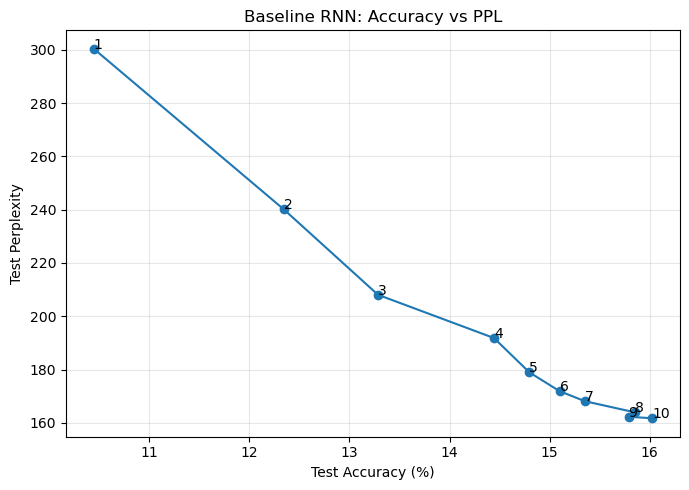

In [10]:
baseline_history = train_model(
    baseline_rnn,
    "Baseline RNN",
    train_loader,
    test_loader,
    epochs=10,
    lr=0.002,
)

### Task 2.3: Variant 1 - Vanilla RNN to LSTM, then Frozen to Fine-Tuned

In [11]:
class LSTMNextWord(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=50,
        hidden_dim=64,
        embedding_weights=None,
        freeze_embeddings=True,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        if embedding_weights is not None:
            self.embedding.weight.data.copy_(embedding_weights)
        self.embedding.weight.requires_grad = not freeze_embeddings

        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=True,
        )
        _, (h_n, _) = self.lstm(packed)
        final_hidden = h_n[-1]
        return self.fc(self.dropout(final_hidden))

RUN 1a - LSTM + frozen GloVe
LSTMNextWord(
  (embedding): Embedding(2576, 50, padding_idx=0)
  (lstm): LSTM(50, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=2576, bias=True)
)
Trainable parameters: 197,136
Non-trainable parameters: 128,800
Epoch 01/10 | LSTM Frozen GloVe | Loss: 5.7823 | Accuracy: 10.13% | PPL: 324.50
Epoch 02/10 | LSTM Frozen GloVe | Loss: 5.6282 | Accuracy: 10.55% | PPL: 278.15
Epoch 03/10 | LSTM Frozen GloVe | Loss: 5.5038 | Accuracy: 12.71% | PPL: 245.62
Epoch 04/10 | LSTM Frozen GloVe | Loss: 5.3995 | Accuracy: 13.13% | PPL: 221.30
Epoch 05/10 | LSTM Frozen GloVe | Loss: 5.3062 | Accuracy: 14.19% | PPL: 201.58
Epoch 06/10 | LSTM Frozen GloVe | Loss: 5.2439 | Accuracy: 14.41% | PPL: 189.41
Epoch 07/10 | LSTM Frozen GloVe | Loss: 5.2051 | Accuracy: 14.61% | PPL: 182.20
Epoch 08/10 | LSTM Frozen GloVe | Loss: 5.1556 | Accuracy: 15.07% | PPL: 173.41
Epoch 09/10 | LSTM Frozen GloVe | Loss: 5.1211 | Accurac

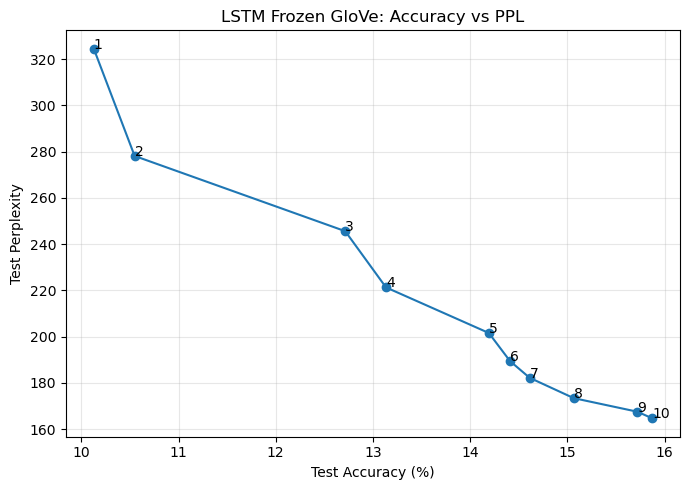

In [12]:
# Run 1a: LSTM + frozen GloVe
lstm_glove = LSTMNextWord(
    len(word2idx), EMBED_DIM, HIDDEN_DIM, glove_weights, freeze_embeddings=True
)
print("RUN 1a - LSTM + frozen GloVe")
count_parameters(lstm_glove)
lstm_glove_history = train_model(
    lstm_glove, "LSTM Frozen GloVe", train_loader, test_loader, epochs=10, lr=0.002
)

RUN 1b - LSTM + fine-tuned GloVe
LSTMNextWord(
  (embedding): Embedding(2576, 50, padding_idx=0)
  (lstm): LSTM(50, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=2576, bias=True)
)
Trainable parameters: 325,936
Non-trainable parameters: 0
Epoch 01/10 | LSTM Fine-Tuned GloVe | Loss: 5.6945 | Accuracy: 10.55% | PPL: 297.21
Epoch 02/10 | LSTM Fine-Tuned GloVe | Loss: 5.4995 | Accuracy: 12.28% | PPL: 244.57
Epoch 03/10 | LSTM Fine-Tuned GloVe | Loss: 5.3087 | Accuracy: 13.62% | PPL: 202.08
Epoch 04/10 | LSTM Fine-Tuned GloVe | Loss: 5.1775 | Accuracy: 14.63% | PPL: 177.24
Epoch 05/10 | LSTM Fine-Tuned GloVe | Loss: 5.0927 | Accuracy: 16.16% | PPL: 162.84
Epoch 06/10 | LSTM Fine-Tuned GloVe | Loss: 5.0277 | Accuracy: 16.75% | PPL: 152.58
Epoch 07/10 | LSTM Fine-Tuned GloVe | Loss: 4.9927 | Accuracy: 17.40% | PPL: 147.33
Epoch 08/10 | LSTM Fine-Tuned GloVe | Loss: 4.9500 | Accuracy: 17.84% | PPL: 141.18
Epoch 09/10 | LSTM Fine-Tu

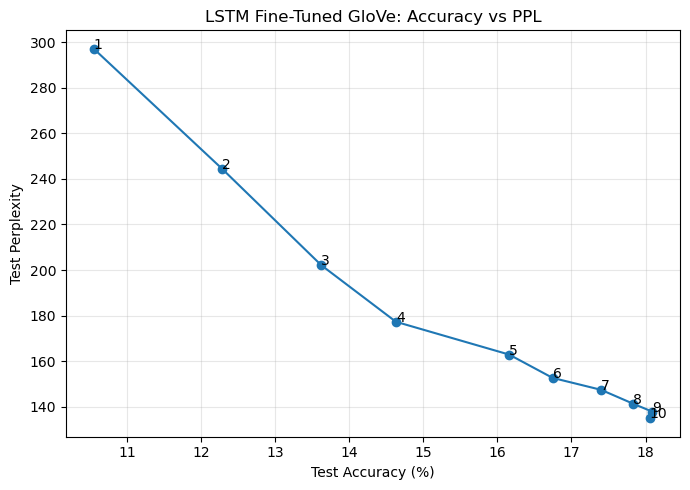

In [13]:
# Run 1b: identical LSTM architecture + fine-tuned GloVe
lstm_glove_finetuned = LSTMNextWord(
    len(word2idx), EMBED_DIM, HIDDEN_DIM, glove_weights.clone(), freeze_embeddings=False
)
print("RUN 1b - LSTM + fine-tuned GloVe")
count_parameters(lstm_glove_finetuned)
lstm_glove_finetuned_history = train_model(
    lstm_glove_finetuned,
    "LSTM Fine-Tuned GloVe",
    train_loader,
    test_loader,
    epochs=10,
    lr=0.002,
)

### Task 2.4: Variant 2 - Domain Adaptation with Custom PyTorch CBOW

In [14]:
class CBOWDataset(Dataset):
    def __init__(self, indexed_sentences):
        self.samples = []
        for sentence in indexed_sentences:
            padded = [PAD_IDX, PAD_IDX] + sentence + [PAD_IDX, PAD_IDX]
            for target_position in range(2, len(padded) - 2):
                context = [
                    padded[target_position - 2],
                    padded[target_position - 1],
                    padded[target_position + 1],
                    padded[target_position + 2],
                ]
                target = padded[target_position]
                self.samples.append((context, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        context, target = self.samples[index]
        return torch.tensor(context, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class CBOWModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=50):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.fc = nn.Linear(embed_dim, vocab_size)

    def forward(self, contexts):
        context_vectors = self.embedding(contexts)
        averaged = torch.mean(context_vectors, dim=1)
        return self.fc(averaged)


cbow_dataset = CBOWDataset(indexed_sentences)
cbow_loader = DataLoader(cbow_dataset, batch_size=BATCH_SIZE, shuffle=True)
print("CBOW samples:", len(cbow_dataset))

CBOW samples: 31394


In [15]:
def train_cbow(model, loader, epochs=5, lr=0.002):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        examples = 0
        for contexts, targets in loader:
            contexts, targets = contexts.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            logits = model(contexts)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * targets.size(0)
            examples += targets.size(0)

        print(f"CBOW Epoch {epoch:02d}/{epochs} | Loss: {loss_sum/examples:.4f}")

    return model


cbow_model = train_cbow(CBOWModel(len(word2idx), EMBED_DIM), cbow_loader, epochs=5)
cbow_weights = cbow_model.embedding.weight.detach().cpu().clone()

CBOW Epoch 01/5 | Loss: 6.7013
CBOW Epoch 02/5 | Loss: 5.6034
CBOW Epoch 03/5 | Loss: 5.1952
CBOW Epoch 04/5 | Loss: 4.8832
CBOW Epoch 05/5 | Loss: 4.6273


LSTM + frozen custom CBOW embeddings
LSTMNextWord(
  (embedding): Embedding(2576, 50, padding_idx=0)
  (lstm): LSTM(50, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=2576, bias=True)
)
Trainable parameters: 197,136
Non-trainable parameters: 128,800
Epoch 01/10 | LSTM CBOW | Loss: 5.5524 | Accuracy: 11.74% | PPL: 257.87
Epoch 02/10 | LSTM CBOW | Loss: 5.3288 | Accuracy: 13.79% | PPL: 206.19
Epoch 03/10 | LSTM CBOW | Loss: 5.2050 | Accuracy: 15.28% | PPL: 182.17
Epoch 04/10 | LSTM CBOW | Loss: 5.1242 | Accuracy: 15.89% | PPL: 168.03
Epoch 05/10 | LSTM CBOW | Loss: 5.0639 | Accuracy: 17.06% | PPL: 158.21
Epoch 06/10 | LSTM CBOW | Loss: 5.0295 | Accuracy: 17.15% | PPL: 152.86
Epoch 07/10 | LSTM CBOW | Loss: 4.9974 | Accuracy: 17.18% | PPL: 148.03
Epoch 08/10 | LSTM CBOW | Loss: 4.9732 | Accuracy: 17.72% | PPL: 144.49
Epoch 09/10 | LSTM CBOW | Loss: 4.9550 | Accuracy: 18.26% | PPL: 141.88
Epoch 10/10 | LSTM CBOW | Loss: 4.9459 |

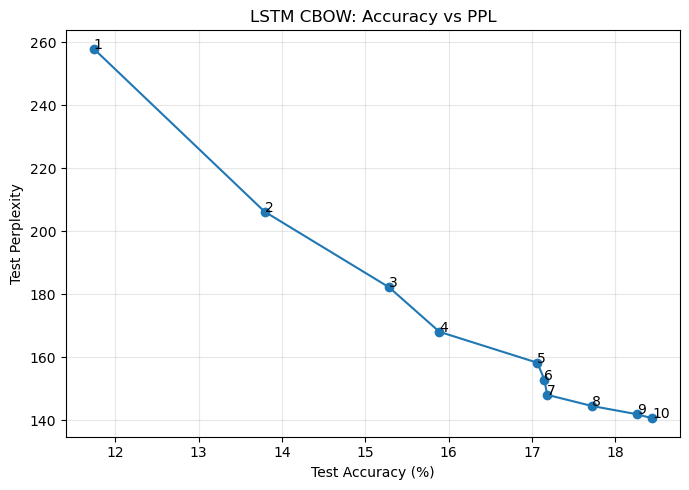

In [16]:
lstm_cbow = LSTMNextWord(
    len(word2idx),
    EMBED_DIM,
    HIDDEN_DIM,
    embedding_weights=cbow_weights,
    freeze_embeddings=True,
)
print("LSTM + frozen custom CBOW embeddings")
count_parameters(lstm_cbow)
lstm_cbow_history = train_model(
    lstm_cbow, "LSTM CBOW", train_loader, test_loader, epochs=10, lr=0.002
)

### Task 2.5: Variant 3 - Standard LSTM with Custom Self-Attention

AttentionLSTM(
  (embedding): Embedding(2576, 50, padding_idx=0)
  (lstm): LSTM(50, 64, batch_first=True)
  (attention): SelfAttention(
    (score): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=2576, bias=True)
)
Trainable parameters: 197,201
Non-trainable parameters: 128,800
Epoch 01/10 | LSTM Attention | Loss: 5.8214 | Accuracy: 8.46% | PPL: 337.46
Epoch 02/10 | LSTM Attention | Loss: 5.7659 | Accuracy: 8.78% | PPL: 319.22
Epoch 03/10 | LSTM Attention | Loss: 5.7112 | Accuracy: 9.44% | PPL: 302.23
Epoch 04/10 | LSTM Attention | Loss: 5.6282 | Accuracy: 10.67% | PPL: 278.16
Epoch 05/10 | LSTM Attention | Loss: 5.5367 | Accuracy: 11.84% | PPL: 253.84
Epoch 06/10 | LSTM Attention | Loss: 5.4498 | Accuracy: 12.68% | PPL: 232.71
Epoch 07/10 | LSTM Attention | Loss: 5.3779 | Accuracy: 13.71% | PPL: 216.57
Epoch 08/10 | LSTM Attention | Loss: 5.3199 | Accuracy: 14.58% | PPL: 204.35
Epoch 09/10 | 

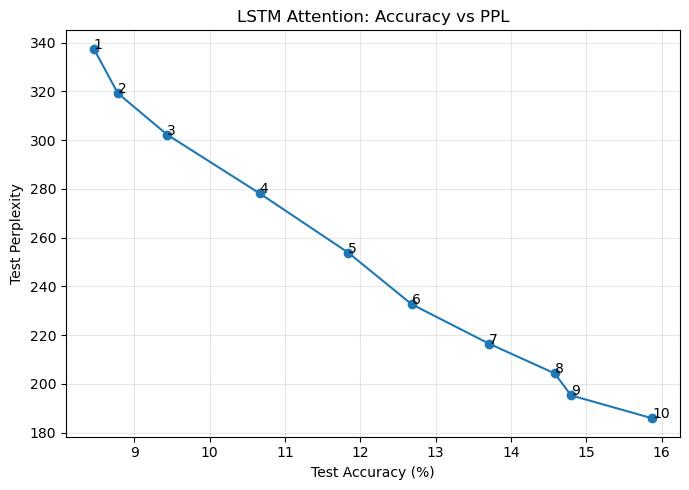

In [17]:
class SelfAttention(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.score = nn.Linear(hidden_dim, 1)

    def forward(self, packed_output, lengths):
        H, _ = pad_packed_sequence(packed_output, batch_first=True)
        S = self.score(H)  # [B, T, 1]

        T_batch = H.size(1)
        time_steps = torch.arange(T_batch, device=H.device).unsqueeze(0)
        padding_mask = time_steps >= lengths.to(H.device).unsqueeze(1)
        S = S.masked_fill(padding_mask.unsqueeze(-1), -1e9)

        A = torch.softmax(S, dim=1)
        C = torch.sum(H * A, dim=1)
        return C, A


class AttentionLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=50, hidden_dim=64, embedding_weights=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        if embedding_weights is not None:
            self.embedding.weight.data.copy_(embedding_weights)
        self.embedding.weight.requires_grad = False

        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.attention = SelfAttention(hidden_dim)
        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, lengths, return_attention=False):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=True,
        )
        packed_output, _ = self.lstm(packed)
        context, attention_weights = self.attention(packed_output, lengths)
        logits = self.fc(self.dropout(context))
        if return_attention:
            return logits, attention_weights
        return logits


lstm_attention = AttentionLSTM(
    len(word2idx), EMBED_DIM, HIDDEN_DIM, embedding_weights=cbow_weights
)
count_parameters(lstm_attention)
lstm_attention_history = train_model(
    lstm_attention,
    "LSTM Attention",
    train_loader,
    test_loader,
    epochs=10,
    lr=0.002,
)

## Section 3: Inference and Performance Evaluation

### Task 3.1: Autoregressive Text Generation Pipeline

In [18]:
def generate(model, seed_text, n_words=10, is_attention=False):
    del is_attention  # kept in the signature required by the assignment
    model.eval()

    seed_tokens = clean_and_tokenize(seed_text)
    context_ids = [word2idx.get(token, UNK_IDX) for token in seed_tokens]
    if not context_ids:
        context_ids = [UNK_IDX]

    generated_tokens = list(seed_tokens)

    with torch.no_grad():
        for _ in range(n_words):
            current_context = context_ids[-MAX_LEN:]
            X = torch.tensor([current_context], dtype=torch.long, device=DEVICE)
            lengths = torch.tensor([len(current_context)], dtype=torch.long)

            logits = model(X, lengths)
            logits[:, PAD_IDX] = -1e9
            logits[:, UNK_IDX] = -1e9

            next_id = int(torch.argmax(logits, dim=1).item())
            context_ids.append(next_id)
            generated_tokens.append(idx2word[next_id])

    return " ".join(generated_tokens)

### Task 3.2: Text Generation, Attention Visualization & Analysis

In [19]:
seeds = ["the white rabbit", "alice was beginning", "said the hatter"]
models_for_generation = {
    "Baseline RNN": baseline_rnn,
    "LSTM + GloVe": lstm_glove,
    "LSTM + CBOW": lstm_cbow,
    "LSTM + Attention": lstm_attention,
}

for model_name, model in models_for_generation.items():
    print(f"\n{model_name}")
    for seed in seeds:
        print(f"  Seed: {seed!r}")
        print(" ", generate(model.to(DEVICE), seed, n_words=10, is_attention=(model_name == "LSTM + Attention")))


Baseline RNN
  Seed: 'the white rabbit'
  the white rabbit , and the queen , and the queen , and
  Seed: 'alice was beginning'
  alice was beginning a little of the rabbit , and the queen ,
  Seed: 'said the hatter'
  said the hatter . the queen , and the queen , and the

LSTM + GloVe
  Seed: 'the white rabbit'
  the white rabbit , and the gryphon , and the gryphon , and
  Seed: 'alice was beginning'
  alice was beginning a little , and she had not to be ,
  Seed: 'said the hatter'
  said the hatter . the queen , and the gryphon , and the

LSTM + CBOW
  Seed: 'the white rabbit'
  the white rabbit was a little thing , and the queen , and
  Seed: 'alice was beginning'
  alice was beginning , and the queen , and the queen , and
  Seed: 'said the hatter'
  said the hatter . the queen . the queen . and the queen

LSTM + Attention
  Seed: 'the white rabbit'
  the white rabbit , said the queen , and the queen was the
  Seed: 'alice was beginning'
  alice was beginning to herself , and she wa

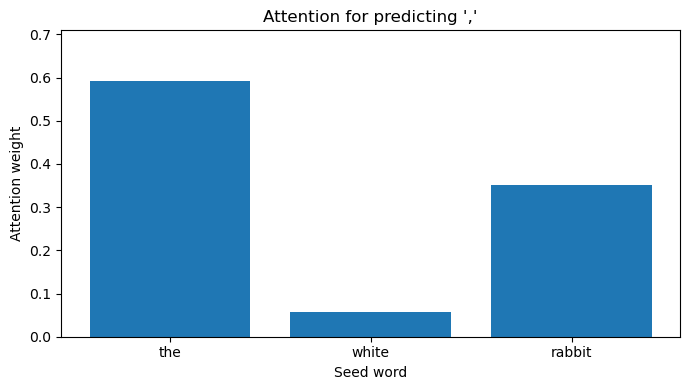

Predicted first target word: ,
Attention weights: {'the': np.float32(0.5910655), 'white': np.float32(0.05758909), 'rabbit': np.float32(0.35134536)}


In [20]:
# Attention weights for the seed phrase when predicting its first generated word.
attention_seed = "the white rabbit"
attention_tokens = clean_and_tokenize(attention_seed)
attention_ids = [word2idx.get(token, UNK_IDX) for token in attention_tokens][-MAX_LEN:]

X_attention = torch.tensor([attention_ids], dtype=torch.long, device=DEVICE)
lengths_attention = torch.tensor([len(attention_ids)], dtype=torch.long)

lstm_attention.eval()
with torch.no_grad():
    logits, A = lstm_attention(X_attention, lengths_attention, return_attention=True)
    logits[:, PAD_IDX] = -1e9
    logits[:, UNK_IDX] = -1e9
    predicted_word = idx2word[int(logits.argmax(dim=1).item())]
    weights = A[0, :len(attention_tokens), 0].detach().cpu().numpy()

plt.figure(figsize=(7, 4))
plt.bar(attention_tokens, weights)
plt.xlabel("Seed word")
plt.ylabel("Attention weight")
plt.title(f"Attention for predicting '{predicted_word}'")
plt.ylim(0, max(weights) * 1.2 if len(weights) else 1)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "attention_the_white_rabbit.png"))
plt.show()

print("Predicted first target word:", predicted_word)
print("Attention weights:", dict(zip(attention_tokens, weights)))

### Comparison Summary

In [21]:
final_results = {
    "Baseline RNN": baseline_history,
    "LSTM + frozen GloVe": lstm_glove_history,
    "LSTM + fine-tuned GloVe": lstm_glove_finetuned_history,
    "LSTM + CBOW": lstm_cbow_history,
    "LSTM + Attention": lstm_attention_history,
}

print(f"{'Model':30s} {'Final Accuracy (%)':>20s} {'Final PPL':>12s}")
print("-" * 66)
for name, history in final_results.items():
    print(f"{name:30s} {history['accuracy'][-1]:20.2f} {history['ppl'][-1]:12.2f}")

Model                            Final Accuracy (%)    Final PPL
------------------------------------------------------------------
Baseline RNN                                  16.02       161.71
LSTM + frozen GloVe                           15.87       164.71
LSTM + fine-tuned GloVe                       18.06       134.85
LSTM + CBOW                                   18.44       140.59
LSTM + Attention                              15.87       185.93
